In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt

## importing the data from the **csv** file 

In [2]:
df=pd.read_csv('credit_risk_dataset.csv')
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


## Exploratory Data Analysis **(EDA)**

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  str    
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  str    
 5   loan_grade                  32581 non-null  str    
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  str    
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), str(4)
memory usage: 3.0 MB


In [4]:
df.isnull().sum()

person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64

In [5]:
df.duplicated().sum()

np.int64(165)

## Dropping Duplicate Rows

In [43]:
df=df.drop_duplicates() # geting rid of all duplicate in the dataset

In [7]:
df.person_age.value_counts()[:10]

person_age
23    3861
22    3607
24    3526
25    3023
26    2462
27    2127
28    1848
29    1682
30    1310
21    1213
Name: count, dtype: int64

In [8]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32416.000000,3.241600e+04,32416.000000,32416.000000,32416.000000,32416.000000,32416.000000,32416.000000
mean,27.747008,6.609164e+04,4.768880,9593.845632,11.014662,0.218688,0.170250,5.811297
std,6.354100,6.201558e+04,4.090411,6322.730241,3.083050,0.413363,0.106812,4.059030
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.854200e+04,2.000000,5000.000000,8.490000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.921800e+04,7.000000,12250.000000,13.110000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [9]:
df.loan_status.value_counts(normalize=True)

loan_status
0    0.781312
1    0.218688
Name: proportion, dtype: float64

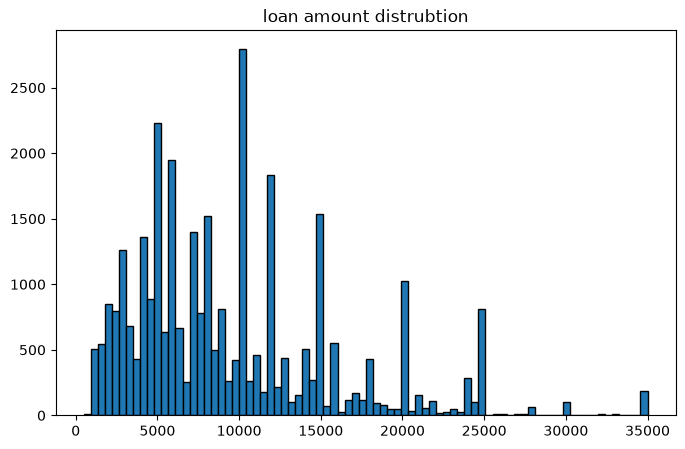

In [10]:
plt.figure(figsize=(8,5))
plt.hist(df['loan_amnt'],bins=80,edgecolor='black',linewidth=1)
plt.title('loan amount distrubtion')
plt.show()

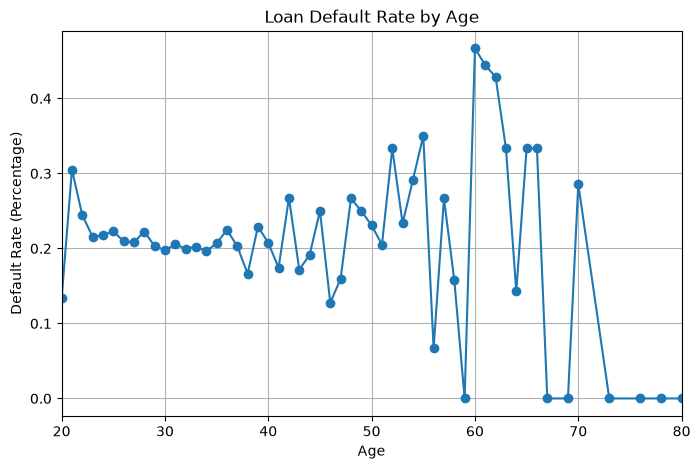

In [11]:
# Calculate default rate per age group
age_default_rate = df.groupby('person_age')['loan_status'].mean()

plt.figure(figsize=(8, 5))
plt.plot(age_default_rate.index, age_default_rate.values, marker='o')
plt.title('Loan Default Rate by Age')
plt.xlabel('Age')
plt.ylabel('Default Rate (Percentage)')
plt.xlim(20, 80) 
plt.grid(True)
plt.show()

In [12]:
import seaborn as sns

#### Correlation matrix graph 

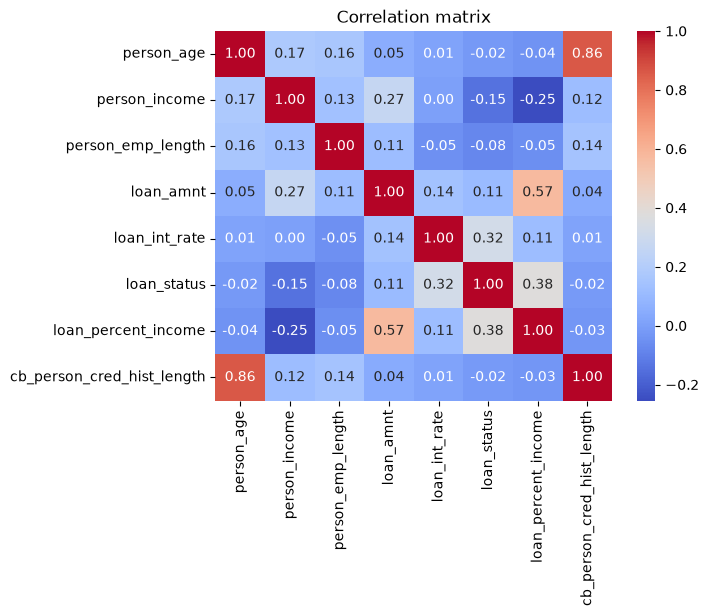

In [13]:
numerical_columns=df.select_dtypes(include='number').columns
sns.heatmap(df[numerical_columns].corr(),annot=True,cmap='coolwarm',fmt='.2f')
plt.title('Correlation matrix')
plt.show()

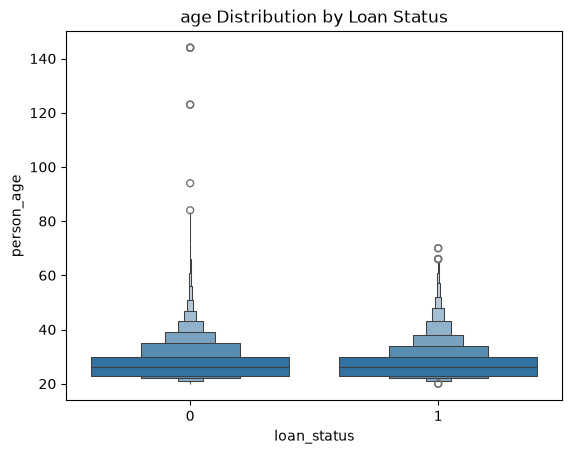

In [14]:
sns.boxenplot(x='loan_status',y='person_age',data=df)
plt.title('age Distribution by Loan Status')
plt.show()

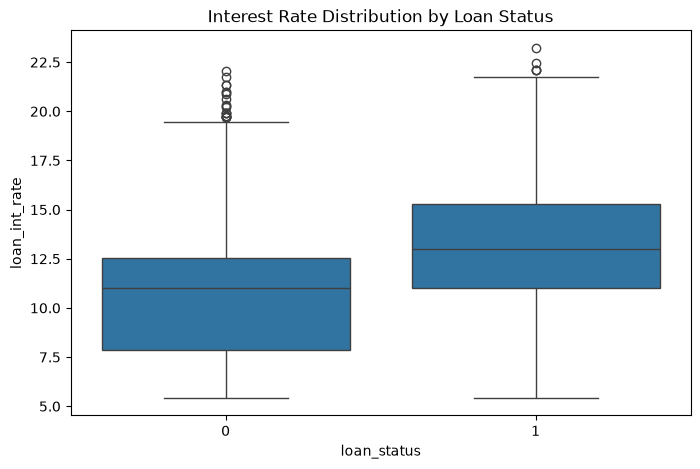

In [15]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='loan_status', y='loan_int_rate', data=df)
plt.title('Interest Rate Distribution by Loan Status')
plt.show()

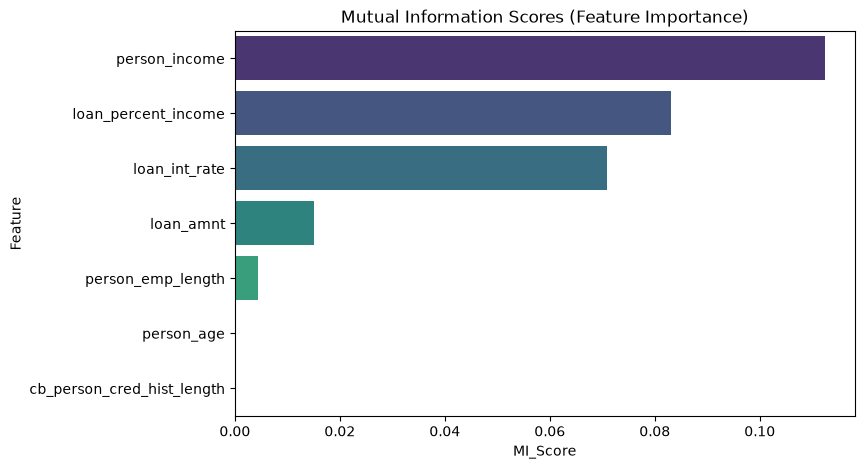

In [116]:
from sklearn.feature_selection import mutual_info_classif

X_num = df[numerical_columns].drop('loan_status', axis=1)
y = df['loan_status']

mi_scores = mutual_info_classif(X_num, y, random_state=42)

mi_scores_df = pd.DataFrame({'Feature': X_num.columns, 'MI_Score': mi_scores})
mi_scores_df = mi_scores_df.sort_values('MI_Score', ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(x='MI_Score', y='Feature', data=mi_scores_df, palette='viridis',hue='Feature', legend=False)
plt.title('Mutual Information Scores (Feature Importance)')
plt.show()

In [18]:
from sklearn.metrics import mutual_info_score

In [20]:
dicts={}
for c in catgrical_columns:
    dicts[c]=mutual_info_score(df[c],df.loan_status)
    

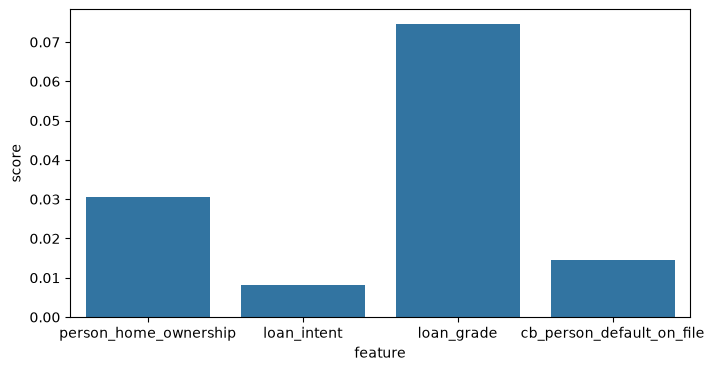

In [21]:
cat_info=pd.DataFrame(dicts.items(),columns=['feature', 'score'])
plt.figure(figsize=(8,4))
sns.barplot(x='feature',y='score',data=cat_info)
plt.show()

## Feature Engineering

In [22]:
df_feature=df.copy()
df_feature['interest_burden'] = df['loan_amnt'] * (df['loan_int_rate'] / 100)
df_feature['income_buffer'] = df['person_income'] - df['loan_amnt']


In [23]:
mutual_info_classif(df_feature[['interest_burden']],df_feature.loan_status)

array([0.06014665])

In [24]:
mutual_info_classif(df_feature[['income_buffer']],df_feature.loan_status)

array([0.08278754])

## Train / Validation / Test Split

In [25]:
from sklearn.model_selection import train_test_split

In [26]:
df_full_train, df_test = train_test_split(df,test_size=0.2, random_state=1,stratify=df_feature['loan_status'])
df_train,df_val =train_test_split(df_full_train,test_size=0.25,random_state=1,stratify=df_full_train['loan_status'])

In [27]:
len(df), len(df_full_train), len(df_test)

(32416, 25932, 6484)

In [28]:
len(df_train), len(df_val)

(19449, 6483)

In [29]:
df_full_train=df_full_train.reset_index(drop=True)

df_train=df_train.reset_index(drop=True)

df_val=df_val.reset_index(drop=True)

df_test=df_test.reset_index(drop=True)

## Data Preprocessing & Feature Pipeline

In [44]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

In [59]:
def encod_normlize(df):
    scale=StandardScaler()
    dv=DictVectorizer(sparse=False)
    imputer=SimpleImputer(strategy='median')
    
    df_copy=df.copy()
    
    y_train=df_copy.loan_status.values
    
    df_copy=df_copy.drop(columns=['loan_status',
                                  'person_age',
                                  'cb_person_cred_hist_length'])
    
    # 1. Impute missing numerical values FIRST  (fit on train)
    num_cols = ['person_emp_length', 'loan_int_rate']
    df_copy[num_cols] = imputer.fit_transform(df_copy[num_cols])
    

    # 2. Engineer features AFTER imputation so there are no NaNs
    df_copy['interest_burden'] = df_copy['loan_amnt'] * (df_copy['loan_int_rate'] / 100)
    df_copy['income_buffer'] = df_copy['person_income'] - df_copy['loan_amnt']
    #3 scale the feturea and make them ready
    numerical=df_copy.select_dtypes(include='number').columns
    catgorucal=df_copy.select_dtypes(include='str').columns
    df_scale=scale.fit_transform(df_copy[numerical])
    
    df_train_dic=df_copy[catgorucal].to_dict(orient='records')
    
    train_enc=dv.fit_transform(df_train_dic)
    X_train = np.hstack((df_scale, train_enc))
    
    return (imputer,scale, dv, X_train,y_train)
    
    
    

In [60]:
def encod_normlize_val(imputer,scale,dv,df):
    
    df_copy=df.copy()
    y_train=df_copy.loan_status.values
    df_copy=df_copy.drop(columns=['loan_status',
                                  'person_age',
                                  'cb_person_cred_hist_length'])
  # 1. Apply the TRAIN medians to val/test using .transform()
    num_cols = ['person_emp_length', 'loan_int_rate']
    df_copy[num_cols] = imputer.transform(df_copy[num_cols])  

    # 2. Engineer features using the imputed values
    df_copy['interest_burden'] = df_copy['loan_amnt'] * (df_copy['loan_int_rate'] / 100)
    df_copy['income_buffer'] = df_copy['person_income'] - df_copy['loan_amnt']
    
    # 3. Transform numerical and categorical columns using train fitters
    numerical=df_copy.select_dtypes(include='number').columns
    catgorucal=df_copy.select_dtypes(include='str').columns
    
    df_scale=scale.transform(df_copy[numerical])
    
    df_train_dic=df_copy[catgorucal].to_dict(orient='records')
    train_enc=dv.transform(df_train_dic)
    X_train = np.hstack((df_scale, train_enc))
    return  (X_train,y_train)

## Model Training & Baseline Comparison

In [77]:
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, roc_auc_score, average_precision_score,
    precision_score, recall_score, f1_score
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier


In [78]:
imputer,scale,dv,x_train,y_train=encod_normlize(df_train)
x_val,y_val=encod_normlize_val(imputer,scale,dv,df_val)

In [81]:
models = {
    "Dummy Classifier":DummyClassifier(),
    "Logistic Regression": LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42),
    "Decision Tree (d=6)": DecisionTreeClassifier(max_depth=6, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, class_weight="balanced", n_jobs=-1, random_state=42)
}

    
results = []

for name, clf in models.items():
    clf.fit(x_train, y_train)
    
    train_proba = clf.predict_proba(x_train)[:, 1]
    val_proba = clf.predict_proba(x_val)[:, 1]
    val_pred = clf.predict(x_val)
    
    results.append({
        "Model": name,
        "Train AUC": round(roc_auc_score(y_train, train_proba), 4),
        "Val AUC": round(roc_auc_score(y_val, val_proba), 4),
        "Val PR-AUC": round(average_precision_score(y_val, val_proba), 4),
        "Accuracy": round(accuracy_score(y_val, val_pred), 4),
        "Recall (1)": round(recall_score(y_val, val_pred), 4),
        "F1 (1)": round(f1_score(y_val, val_pred), 4),
    })

results_df = pd.DataFrame(results).sort_values("Val AUC", ascending=False)
results_df

,Model,Train AUC,Val AUC,Val PR-AUC,Accuracy,Recall (1),F1 (1)
3,Random Forest,1.0000,0.9294,0.8812,0.9224,0.7518,0.8091
2,Decision Tree (d=6),0.8986,0.8960,0.8270,0.9021,0.7179,0.7623
1,Logistic Regression,0.8700,0.8725,0.7248,0.8075,0.7800,0.6393
0,Dummy Classifier,0.5000,0.5000,0.2187,0.7813,0.0000,0.0000


## fine tuning the best overall model

*Preparing the full training set (df_train+df_val) and test set*

In [82]:
imnputer,scale,dv,x_full_train,y_full_train= encod_normlize(df_full_train)
x_test,y_test=encod_normlize_val(imnputer,scale,dv,df_test)

In [97]:
from sklearn.model_selection import RandomizedSearchCV

In [102]:
param_dist = {
    'n_estimators': [200, 300, 500],
    'max_depth': [10, 14, 18, 24, None],
    'min_samples_leaf': [1, 2, 4, 8],
    'max_features': ['sqrt', 'log2'],
    'class_weight': ['balanced', 'balanced_subsample', None],
}

In [103]:
forestClasfier=RandomForestClassifier(random_state=42)
grid=RandomizedSearchCV(estimator=forestClasfier,
                        param_distributions=param_dist,
                        n_jobs=-2,
                        scoring='roc_auc',
                       cv=5,
                       random_state=2,
                       n_iter=25
                       )

In [104]:
grid.fit(x_train,y_train)


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'class_weight': ['balanced', 'balanced_subsample', ...], 'max_depth': [10, 14, ...], 'max_features': ['sqrt', 'log2'], 'min_samples_leaf': [1, 2, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",25
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-2
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",2
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSe

In [113]:
best_model=grid.best_estimator_
train_auc = roc_auc_score(y_train, best_model.predict_proba(x_train)[:, 1])
val_proba = best_model.predict_proba(x_val)[:, 1]
val_auc = roc_auc_score(y_val, val_proba)

print(f"Tuned Train AUC: {train_auc:.4f} | Tuned Val AUC: {val_auc:.4f}\n")

for thresh in [0.50, 0.45, 0.40, 0.35]:
    preds = (val_proba >= thresh).astype(int)
    print(
        f"Threshold {thresh:.2f} | "
        f"Recall: {recall_score(y_val, preds):.4f} | "
        f"Precision: {precision_score(y_val, preds):.4f} | "
        f"F1: {f1_score(y_val, preds):.4f}"
    )

Tuned Train AUC: 0.9925 | Tuned Val AUC: 0.9303

Threshold 0.50 | Recall: 0.7546 | Precision: 0.8756 | F1: 0.8106
Threshold 0.45 | Recall: 0.7779 | Precision: 0.8244 | F1: 0.8004
Threshold 0.40 | Recall: 0.7969 | Precision: 0.7589 | F1: 0.7774
Threshold 0.35 | Recall: 0.8181 | Precision: 0.6701 | F1: 0.7367


## Evaluating on the Test Set

In [114]:
from sklearn.metrics import classification_report, confusion_matrix

final_rf = RandomForestClassifier(**grid.best_params_, random_state=42, n_jobs=-1)
final_rf.fit(x_full_train, y_full_train)

test_proba = final_rf.predict_proba(x_test)[:, 1]
test_pred = (test_proba >= 0.45).astype(int) 

print(f"Final Test ROC-AUC: {roc_auc_score(y_test, test_proba):.4f}")
print(f"Final Test PR-AUC:  {average_precision_score(y_test, test_proba):.4f}\n")
print(classification_report(y_test, test_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, test_pred))

Final Test ROC-AUC: 0.9386
Final Test PR-AUC:  0.8901

              precision    recall  f1-score   support

           0       0.94      0.95      0.94      5066
           1       0.81      0.77      0.79      1418

    accuracy                           0.91      6484
   macro avg       0.87      0.86      0.87      6484
weighted avg       0.91      0.91      0.91      6484

Confusion Matrix:
 [[4811  255]
 [ 324 1094]]


## Saving the Model Bundle

In [115]:
import joblib

model_bundle = {
    "imputer": imnputer,
    "scaler": scale,
    "vectorizer": dv,
    "model": final_rf,
    "threshold": 0.45
}

joblib.dump(model_bundle, "credit_risk_rf_model.joblib")
print("Model bundle saved successfully!")

Model bundle saved successfully!


## FEATURE IMPORTANCE

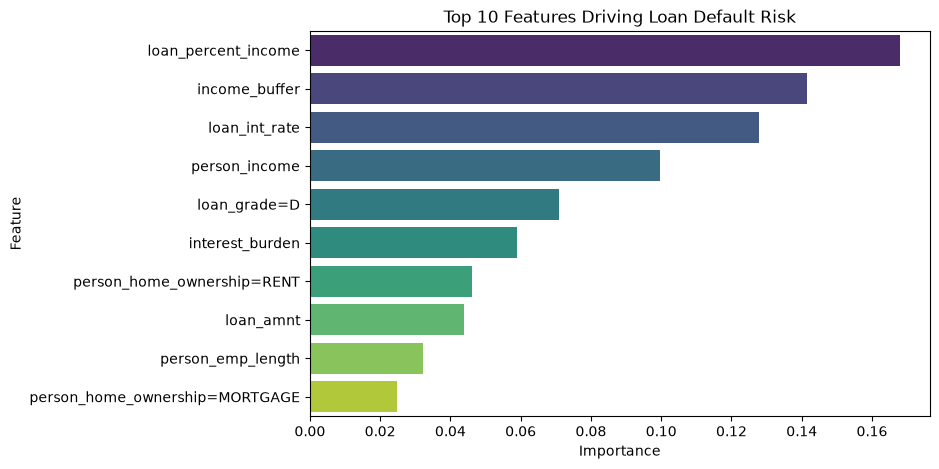

In [118]:
num_features = ['person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 
                'loan_percent_income', 'interest_burden', 'income_buffer']
all_features = num_features + list(dv.get_feature_names_out())

imp_df = pd.DataFrame({'Feature': all_features, 'Importance': final_rf.feature_importances_})
imp_df = imp_df.sort_values('Importance', ascending=False).head(10)

plt.figure(figsize=(8, 5))
sns.barplot(x='Importance', y='Feature', data=imp_df, palette='viridis', hue='Feature', legend=False)
plt.title('Top 10 Features Driving Loan Default Risk')
plt.show()